# Etapa 2 · Extracción, limpieza y transformación de datos
**Reto Global Classroom – Analítica de Airbnb** · Rol: Ingeniería de datos

**Ciudad/región seleccionada:** Hawái, EE. UU. (islas de Maui, Oahu/Honolulu, Hawái y Kauai) · **Fuente:** `listings.csv` detallado de [Inside Airbnb](https://insideairbnb.com/get-the-data/), scrape de septiembre de 2026.

Este cuaderno toma el archivo crudo y produce dos conjuntos de datos listos para las etapas siguientes:

| Archivo | Para qué sirve |
|---|---|
| `listings_clean.csv` | Datos limpios y legibles (categorías como texto). Entrada del análisis exploratorio y del tablero. |
| `listings_model.csv` | Mismos registros, todo numérico (categóricas codificadas *one-hot*). Entrada de los modelos de regresión y clasificación. |

**Contenido**
1. Carga y análisis exploratorio inicial
2. Selección de variables
3. Corrección de tipos y formatos
4. Variable objetivo: precio por noche
5. Ingeniería de características
6. Tratamiento de datos faltantes
7. Consistencia de variables categóricas
8. Análisis y tratamiento de outliers
9. Codificación
10. Validación final y exportación
11. Resumen para el reporte

In [3]:
import json
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 200)

# Estilo único para todas las gráficas
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 9,
})

# Ruta del archivo crudo. Funciona igual con listings.csv o listings.csv.gz
DATA_PATH = os.environ.get("LISTINGS_PATH", "listings.csv")
OUT_DIR = os.environ.get("OUT_DIR", ".")

## 1. Carga y análisis exploratorio inicial

In [4]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Registros: {raw.shape[0]:,}  |  Variables: {raw.shape[1]}")
raw.head(3)

Registros: 38,779  |  Variables: 90


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,784020,https://www.airbnb.com/rooms/784020,20260917204833,2026-09-21,NaN,#1 Guest Favorite for Napili & Kapalua Bays!,Enjoy this luxury residence with beautiful bam...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,4134387,https://www.airbnb.com/users/show/4134387,1462533788759355031,https://www.airbnb.com/users/profile/146253378...,Jeff,NaN,13,10,13,10,"Lahaina, HI",I love hospitality and helping people create s...,NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/14ecd...,NaN,2,NaN,NaN,t,t,NaN,Lahaina,Maui,20.995184,-156.665009,Entire townhouse,Entire home/apt,8,NaN,2.5 baths,3.0,5.0,"[""Long term stays allowed"", ""Children\u2019s d...",$848.33,2026-09-23,2026-09-26,2545.0,848.33,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",3.0,1125.0,3.0,3.0,1125.0,1125.0,3.0,1125.0,NaN,t,15,31,42,192,2026-09-21,169,27,0,42,30,162,137429.0,2017-04-26,2026-07-21,4.96,4.97,4.92,4.97,4.93,4.97,4.80,"430020680015, TA-094-797-4144-00",NaN,1,1,0,0,1.48
1,461638,https://www.airbnb.com/rooms/461638,20260917204833,2026-09-19,NaN,The Lotus Garden-Sugar Room/Downtown Hilo,If you want a convenient base for seeing the i...,NaN,https://a0.muscache.com/pictures/99ab04c0-eb8b...,2128914,https://www.airbnb.com/users/show/2128914,1462522384134588935,https://www.airbnb.com/users/profile/146252238...,Megan,NaN,14,5,14,5,"Hilo, HI",Aloha I'm Megan. Meet Jasper also. We've been ...,NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/users/2128914/profi...,NaN,5,NaN,NaN,t,t,NaN,South Hilo,Hawaii,19.721000,-155.084950,Private room in cottage,Private room,1,NaN,1 shared bath,1.0,1.0,"[""Long term stays allowed"", ""Kitchen"", ""Free s...",$101.86,2026-09-19,2026-09-26,713.0,101.86,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",7.0,180.0,7.0,7.0,180.0,180.0,7.0,180.0,NaN,t,30,60,90,90,2026-09-19,438,3,0,90,0,42,4278.0,2012-05-18,2026-08-12,4.68,4.74,4.81,4.83,4.82,4.81,4.59,W85296321-01,NaN,5,3,2,0,2.51
2,479121,https://www.airbnb.com/rooms/479121,20260917204833,2026-09-19,NaN,Tropical Relaxing Loft: Spacious and Unique,Tucked in a quiet ocean side area on the east ...,NaN,https://a0.muscache.com/pictures/05bd7136-dc5e...,4599607,https://www.airbnb.com/users/show/4599607,1462661189318434518,https://www.airbnb.com/users/profile/146266118...,SherylRose,NaN,13,8,13,4,"California, United States

In [5]:
# Número de variables por tipo
tipos = raw.dtypes.astype(str).replace({"object": "texto", "str": "texto", "string": "texto",
                                        "int64": "entero", "float64": "decimal"})
print(tipos.value_counts().to_string())
print(f"\nIDs duplicados: {raw['id'].duplicated().sum()}  |  Filas duplicadas completas: {raw.duplicated().sum()}")

decimal    36
texto      30
entero     24

IDs duplicados: 0  |  Filas duplicadas completas: 0


In [6]:
# Diccionario rápido: tipo, % nulos, cardinalidad y un ejemplo por variable
perfil = pd.DataFrame({
    "tipo": tipos,
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(1),
    "valores únicos": raw.nunique(),
    "ejemplo": raw.apply(lambda s: str(s.dropna().iloc[0])[:45] if s.notna().any() else "—"),
})
perfil

,tipo,nulos,% nulos,valores únicos,ejemplo
id,entero,0,0.0,38779,784020
listing_url,texto,0,0.0,38779,https://www.airbnb.com/rooms/784020
scrape_id,entero,0,0.0,1,20260917204833
last_scraped,texto,0,0.0,3,2026-09-21
source,texto,36067,93.0,1,previous scrape
name,texto,0,0.0,35188,#1 Guest Favorite for Napili & Kapalua Bays!
description,texto,28,0.1,31118,Enjoy this luxury residence with beautiful ba
neighborhood_overview,decimal,38779,100.0,0,—
picture_url,texto,0,0.0,37438,https://a0.muscache.com/pictures/hosting/Host
host_id,entero,0,0.0,9306,4134387


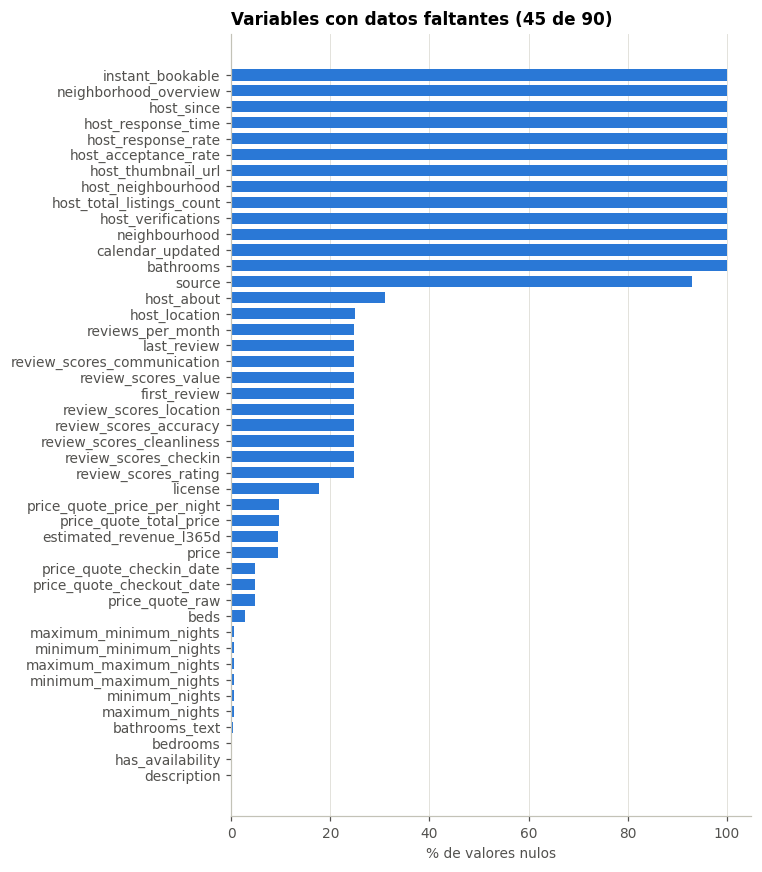

Variables 100 % vacías (13): ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url', 'host_neighbourhood', 'host_total_listings_count', 'host_verifications', 'neighbourhood', 'bathrooms', 'calendar_updated', 'instant_bookable']
Variables con un solo valor: ['scrape_id', 'source']


In [7]:
nul = perfil.loc[perfil["% nulos"] > 0, "% nulos"].sort_values()
fig, ax = plt.subplots(figsize=(7, 8))
ax.barh(nul.index, nul.values, color=AZUL, height=0.7)
ax.set_xlabel("% de valores nulos")
ax.set_title(f"Variables con datos faltantes ({len(nul)} de {raw.shape[1]})")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

vacias = perfil.index[perfil["% nulos"] == 100].tolist()
constantes = perfil.index[(perfil["valores únicos"] == 1) & (perfil["% nulos"] < 100)].tolist()
print(f"Variables 100 % vacías ({len(vacias)}): {vacias}")
print(f"Variables con un solo valor: {constantes}")

In [8]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
id,38779.0,8.228221e+17,6.528497e+17,5.269000e+03,4.775115e+07,9.064377e+17,1.437805e+18,1.776542e+18
scrape_id,38779.0,2.026092e+13,1.927000e+01,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13,2.026092e+13
neighborhood_overview,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
host_id,38779.0,4.793118e+16,2.822650e+17,8.840000e+02,4.306839e+07,1.513984e+08,4.409130e+08,1.774765e+18
host_profile_id,38779.0,1.479523e+18,5.011571e+16,1.462506e+18,1.463185e+18,1.467351e+18,1.469877e+18,1.776542e+18
host_since,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hosts_time_as_user_years,38779.0,7.530000e+00,3.970000e+00,0.000000e+00,4.000000e+00,8.000000e+00,1.100000e+01,1.800000e+01
hosts_time_as_user_months,38779.0,5.520000e+00,3.510000e+00,0.000000e+00,3.000000e+00,5.000000e+00,9.000000e+00,1.100000e+01
hosts_time_as_host_years,38779.0,6.430000e+00,3.880000e+00,0.000000e+00,3.000000e+00,6.000000e+00,1.000000e+01,1.500000e+01
hosts_time_as_host_months,38779.0,5.670000e+00,3.500000e+00,0.000000e+00,3.000000e+00,6.000000e+00,9.000000e+00,1.100000e+01


**Hallazgos del análisis inicial**

- No hay registros duplicados; cada fila es un anuncio único (`id`).
- 13 variables vienen **completamente vacías** en esta versión del scrape (por ejemplo `bathrooms`, `host_since`, `host_response_rate`, `instant_bookable`, `neighbourhood`). No aportan información y se eliminan.
- `price` llega como texto (`"$848.33"`) y falta en ~9 % de los anuncios.
- Las variables de reseñas (`review_scores_*`, `first_review`, `last_review`, `reviews_per_month`) faltan en ~25 % de los anuncios: son exactamente los que **no tienen reseñas**, no un error de captura.
- Los booleanos vienen como `"t"`/`"f"`, las fechas como texto y `amenities` como una lista JSON dentro de una celda.
- Hay valores extremos evidentes: `maximum_nights` llega a 2 147 483 647 (valor centinela), `minimum_nights` a 720 y el precio por noche a más de 90 000 USD.

## 2. Selección de variables

Se conservan solo las variables potencialmente relevantes para estimar el precio y para clasificar anuncios como recomendables. Se descartan, con su razón:

In [9]:
descartes = {
    "100 % vacías": vacias,
    "Identificadores y URLs (no describen el inmueble)": [
        "listing_url", "scrape_id", "picture_url", "host_id", "host_url", "host_profile_id",
        "host_profile_url", "host_name", "host_picture_url"],
    "Metadatos del scrape": ["source", "calendar_last_scraped"],
    "Texto libre (requeriría NLP; fuera del alcance)": ["name", "description", "host_about"],
    "Redundantes con otra variable que sí se conserva": [
        "minimum_minimum_nights", "maximum_minimum_nights", "minimum_maximum_nights",
        "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm",
        "host_listings_count", "calculated_host_listings_count_entire_homes",
        "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
        "availability_60", "availability_90", "availability_eoy", "number_of_reviews_ly",
        "hosts_time_as_user_years", "hosts_time_as_user_months"],
    "Fuga de información (se calculan a partir del precio)": [
        "estimated_revenue_l365d", "price_quote_total_price", "price_quote_price_per_night", "price_quote_raw"],
}
for razon, cols in descartes.items():
    print(f"{razon} ({len(cols)}):\n   {', '.join(cols)}\n")

100 % vacías (13):
   neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, bathrooms, calendar_updated, instant_bookable

Identificadores y URLs (no describen el inmueble) (9):
   listing_url, scrape_id, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_name, host_picture_url

Metadatos del scrape (2):
   source, calendar_last_scraped

Texto libre (requeriría NLP; fuera del alcance) (3):
   name, description, host_about

Redundantes con otra variable que sí se conserva (16):
   minimum_minimum_nights, maximum_minimum_nights, minimum_maximum_nights, maximum_maximum_nights, minimum_nights_avg_ntm, maximum_nights_avg_ntm, host_listings_count, calculated_host_listings_count_entire_homes, calculated_host_listings_count_private_rooms, calculated_host_listings_count_shared_rooms, availability_60, availability_90, availability_e

Antes de descartar las variables redundantes y las de cotización se verifican dos supuestos:
que `price` es el mismo número que `price_quote_price_per_night`, y que las variantes de noches mínimas están altamente correlacionadas entre sí.

In [10]:
precio_tmp = pd.to_numeric(raw["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
ambos = precio_tmp.notna() & raw["price_quote_price_per_night"].notna()
iguales = np.isclose(precio_tmp[ambos], raw.loc[ambos, "price_quote_price_per_night"], atol=0.01).mean()
print(f"`price` coincide con `price_quote_price_per_night` en el {iguales:.1%} de los {ambos.sum():,} casos con ambos valores")

print("\nCorrelación de Spearman entre variables candidatas a redundantes:")
print(raw[["minimum_nights", "minimum_minimum_nights", "minimum_nights_avg_ntm"]].corr(method="spearman").round(2).to_string())
print()
print(raw[["availability_30", "availability_60", "availability_90"]].corr(method="spearman").round(2).to_string())
print()
print(raw[["host_listings_count", "calculated_host_listings_count"]].corr(method="spearman").round(2).to_string())

`price` coincide con `price_quote_price_per_night` en el 100.0% de los 35,021 casos con ambos valores

Correlación de Spearman entre variables candidatas a redundantes:
                        minimum_nights  minimum_minimum_nights  minimum_nights_avg_ntm
minimum_nights                    1.00                    1.00                    0.82
minimum_minimum_nights            1.00                    1.00                    0.82
minimum_nights_avg_ntm            0.82                    0.82                    1.00

                 availability_30  availability_60  availability_90
availability_30             1.00             0.92             0.86
availability_60             0.92             1.00             0.96
availability_90             0.86             0.96             1.00

                                host_listings_count  calculated_host_listings_count
host_listings_count                            1.00                            0.95
calculated_host_listings_count               

In [11]:
# Algunas columnas "descartadas" se usan primero para derivar características (sección 5),
# así que aquí solo se eliminan las que no se necesitan más.
usar_despues = {"price_quote_raw", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm"}
eliminar = [c for cols in descartes.values() for c in cols if c not in usar_despues]
df = raw.drop(columns=eliminar).copy()
print(f"Variables: {raw.shape[1]} -> {df.shape[1]}")

Variables: 90 -> 46


## 3. Corrección de tipos y formatos

In [12]:
# Precio: de texto "$1,234.56" a número
df["price"] = pd.to_numeric(df["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")

# Booleanos "t"/"f" -> 1/0 (se deja NaN donde falte, para tratarlo en la sección 6)
for c in ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]:
    df[c] = df[c].map({"t": 1, "f": 0})

# Fechas: de texto a datetime
for c in ["last_scraped", "first_review", "last_review", "price_quote_checkin_date", "price_quote_checkout_date"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

# Texto categórico: sin espacios sobrantes
for c in ["neighbourhood_cleansed", "neighbourhood_group_cleansed", "property_type", "room_type"]:
    df[c] = df[c].str.strip()

df[["price", "host_is_superhost", "has_availability", "last_scraped", "first_review", "price_quote_checkin_date"]].dtypes

price                              float64
host_is_superhost                    int64
has_availability                   float64
last_scraped                datetime64[ns]
first_review                datetime64[ns]
price_quote_checkin_date    datetime64[ns]
dtype: object

## 4. Variable objetivo: precio por noche

En esta versión de los datos, `price` no es un precio "de lista" fijo: es el **precio por noche de una cotización real** hecha por el scraper para unas fechas concretas (`price_quote_checkin_date` → `price_quote_checkout_date`). Por eso el precio depende también de cuándo y por cuántas noches se cotizó, y esas dos cosas se conservan como características.

¿Por qué falta el precio en ~9 % de los anuncios?

In [13]:
def leer_cotizacion(txt):
    """Extrae del JSON de la cotización si estaba disponible y si se cotizó por mes."""
    if not isinstance(txt, str):
        return pd.Series({"cot_disponible": np.nan, "cot_mensual": np.nan})
    q = json.loads(txt).get("quote", {})
    return pd.Series({"cot_disponible": q.get("is_available"), "cot_mensual": q.get("is_monthly_priced")})

cot = df["price_quote_raw"].apply(leer_cotizacion)
sin_precio = df["price"].isna()
motivo = np.select(
    [cot["cot_disponible"].isna(), cot["cot_mensual"] == True, cot["cot_disponible"] == False],
    ["sin cotización", "cotizado por mes (sin precio por noche)", "no disponible en las fechas consultadas"],
    default="otro")
print(f"Anuncios sin precio: {sin_precio.sum():,} ({sin_precio.mean():.1%})\n")
print(pd.Series(motivo[sin_precio]).value_counts().to_string())

Anuncios sin precio: 3,654 (9.4%)

sin cotización                             1877
no disponible en las fechas consultadas    1481
cotizado por mes (sin precio por noche)     296


El precio falta porque el anuncio no estaba disponible, no pudo cotizarse o solo ofrece tarifa mensual. Como es la **variable objetivo**, imputarla sería inventar la respuesta que el modelo debe aprender: estos registros se **eliminan**.

In [14]:
n0 = len(df)
df = df[df["price"].notna()].drop(columns="price_quote_raw").reset_index(drop=True)
print(f"Registros: {n0:,} -> {len(df):,}  (se eliminan {n0 - len(df):,})")

Registros: 38,779 -> 35,125  (se eliminan 3,654)


## 5. Ingeniería de características

### 5.1 Baños
`bathrooms` viene vacía; la información está en `bathrooms_text` ("2.5 baths", "1 shared bath", "Half-bath"). Se separa en número de baños y si el baño es compartido.

In [15]:
bt = df["bathrooms_text"].str.lower()
df["bathrooms"] = pd.to_numeric(bt.str.extract(r"(\d+\.?\d*)")[0], errors="coerce")
df.loc[bt.str.contains("half", na=False) & df["bathrooms"].isna(), "bathrooms"] = 0.5
df["bath_shared"] = bt.str.contains("shared", na=False).astype(int)
df = df.drop(columns="bathrooms_text")
df[["bathrooms", "bath_shared"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
bathrooms,35016.0,1.73,1.12,0.0,1.0,1.0,2.0,14.0
bath_shared,35125.0,0.02,0.14,0.0,0.0,0.0,0.0,1.0


### 5.2 Antigüedad del anfitrión, licencia y ubicación del anfitrión

In [16]:
# Años como anfitrión (años + meses en una sola variable continua)
df["host_years"] = (df["hosts_time_as_host_years"] + df["hosts_time_as_host_months"] / 12).round(2)

# Licencia: el número en sí no sirve, pero tenerla registrada sí puede ser señal de formalidad
df["has_license"] = df["license"].notna().astype(int)

# Anfitrión local (vive en Hawái) vs. remoto vs. no informa
loc = df["host_location"].fillna("")
df["host_location_group"] = np.select(
    [loc == "", loc.str.contains(r", HI$|Hawaii", regex=True)],
    ["Unknown", "Hawaii"], default="Elsewhere")

df = df.drop(columns=["hosts_time_as_host_years", "hosts_time_as_host_months", "license", "host_location"])
print(df["host_location_group"].value_counts(normalize=True).round(3).to_string())
print(f"\nCon licencia registrada: {df['has_license'].mean():.1%}")

host_location_group
Hawaii       0.524
Unknown      0.256
Elsewhere    0.221

Con licencia registrada: 82.6%


### 5.3 Características de la cotización
Noches cotizadas, días de anticipación entre el scrape y el check-in, y mes del check-in (temporada).

In [17]:
df["quote_nights"] = (df["price_quote_checkout_date"] - df["price_quote_checkin_date"]).dt.days
df["quote_lead_days"] = (df["price_quote_checkin_date"] - df["last_scraped"]).dt.days.clip(lower=0)
df["quote_checkin_month"] = df["price_quote_checkin_date"].dt.month
df[["quote_nights", "quote_lead_days", "quote_checkin_month"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
quote_nights,35125.0,6.4,19.6,1.0,1.0,2.0,4.0,365.0
quote_lead_days,35125.0,19.2,43.1,0.0,1.0,5.0,15.0,364.0
quote_checkin_month,35125.0,9.1,1.6,1.0,9.0,9.0,10.0,12.0


### 5.4 Reseñas
Las fechas de primera y última reseña se convierten en duraciones respecto a la fecha del scrape, que son directamente utilizables por un modelo.

In [18]:
df["has_reviews"] = (df["number_of_reviews"] > 0).astype(int)
df["days_since_last_review"] = (df["last_scraped"] - df["last_review"]).dt.days
df["months_since_first_review"] = ((df["last_scraped"] - df["first_review"]).dt.days / 30.44).round(1)
df = df.drop(columns=["first_review", "last_review", "last_scraped", "price_quote_checkout_date"])
print(f"Anuncios con al menos una reseña: {df['has_reviews'].mean():.1%}")

Anuncios con al menos una reseña: 76.6%


### 5.5 Amenidades
`amenities` es una lista JSON con más de 6 000 textos distintos (muchos son variantes del mismo servicio, p. ej. *"Free parking on premises"*, *"Free street parking"*). Se resume en:
- `n_amenities`: cuántas amenidades declara el anuncio.
- Indicadores 0/1 para amenidades con sentido de negocio, detectadas por palabra clave para agrupar variantes.

Amenidades distintas: 6,632



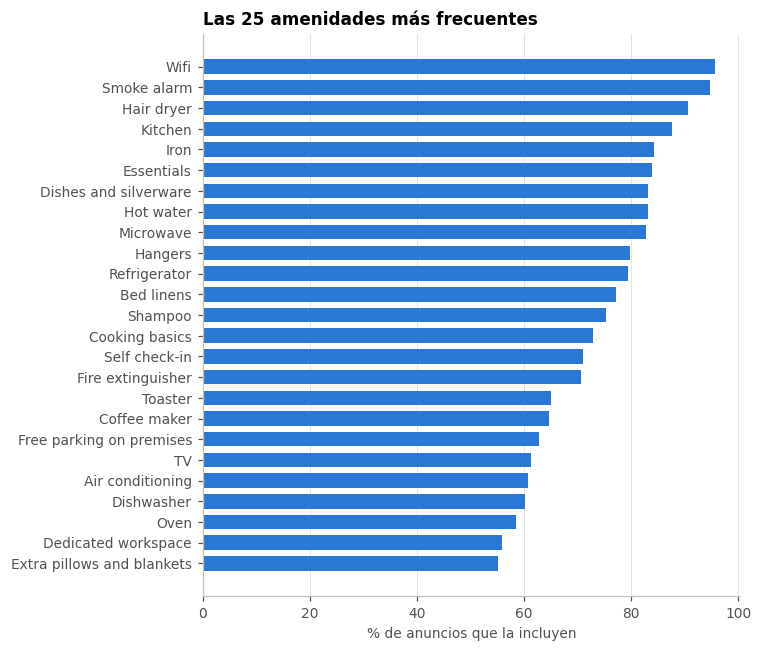

In [19]:
amen = df["amenities"].apply(json.loads)
conteo = Counter(a for lista in amen for a in lista)
print(f"Amenidades distintas: {len(conteo):,}\n")
top = pd.Series(conteo).sort_values(ascending=False).head(25) / len(df) * 100
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index[::-1], top.values[::-1], color=AZUL, height=0.7)
ax.set_xlabel("% de anuncios que la incluyen")
ax.set_title("Las 25 amenidades más frecuentes")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [20]:
PATRONES = {
    "am_wifi": r"wifi",
    "am_kitchen": r"^kitchen$|^kitchenette$",
    "am_air_conditioning": r"air conditioning|^ac\b",
    "am_free_parking": r"free .*parking|free carport|free driveway",
    "am_pool": r"^(?!.*pool table).*\bpool\b",
    "am_hot_tub": r"hot tub",
    "am_washer": r"\bwasher",
    "am_dishwasher": r"dishwasher",
    "am_tv": r"\btv\b|hdtv",
    "am_bbq": r"bbq|barbecue",
    "am_beach_waterfront": r"beach access|waterfront",
    "am_ocean_view": r"ocean view|beach view|sea view",
    "am_gym": r"\bgym\b|exercise equipment",
    "am_elevator": r"elevator",
    "am_self_checkin": r"self check-in",
    "am_workspace": r"dedicated workspace",
    "am_patio_balcony": r"patio or balcony",
}
partes = amen.apply(lambda lista: [x.lower() for x in lista])
for col, pat in PATRONES.items():
    rx = re.compile(pat)
    df[col] = partes.apply(lambda lista: int(any(rx.search(x) for x in lista)))
df["n_amenities"] = amen.apply(len)
df = df.drop(columns="amenities")

(df[list(PATRONES)].mean() * 100).round(1).sort_values(ascending=False).rename("% de anuncios").to_frame()

,% de anuncios
am_wifi,99.0
am_tv,95.9
am_kitchen,91.0
am_washer,81.5
am_pool,78.9
am_air_conditioning,76.6
am_free_parking,75.8
am_self_checkin,70.9
am_patio_balcony,70.6
am_bbq,68.2


### 5.6 Estancias largas
En Hawái hay regulación sobre alquileres de corta estancia; los anuncios con mínimo de 30 noches o más operan en un mercado distinto (alquiler mensual). Se marca con un indicador.

In [21]:
df["long_stay"] = (df["minimum_nights"].fillna(df["minimum_nights_avg_ntm"]) >= 30).astype(int)
print(f"Anuncios con estancia mínima >= 30 noches: {df['long_stay'].mean():.1%}")

Anuncios con estancia mínima >= 30 noches: 6.2%


## 6. Tratamiento de datos faltantes

Estado después de la selección y la ingeniería de características:

In [22]:
def tabla_nulos(d):
    t = pd.DataFrame({"nulos": d.isna().sum(), "% nulos": (d.isna().mean() * 100).round(2)})
    return t[t["nulos"] > 0].sort_values("nulos", ascending=False)

tabla_nulos(df)

,nulos,% nulos
review_scores_accuracy,8210,23.37
review_scores_cleanliness,8210,23.37
review_scores_checkin,8210,23.37
review_scores_communication,8210,23.37
review_scores_location,8210,23.37
review_scores_value,8210,23.37
review_scores_rating,8207,23.37
reviews_per_month,8207,23.37
days_since_last_review,8207,23.37
months_since_first_review,8207,23.37


**Estrategia por variable**

| Variable | Causa del faltante | Tratamiento |
|---|---|---|
| `review_scores_*` (7) | El anuncio no tiene reseñas | Mediana de la variable + el indicador `has_reviews` conserva la información de que no había dato |
| `reviews_per_month` | El anuncio no tiene reseñas | 0 (valor real: cero reseñas por mes) |
| `days_since_last_review`, `months_since_first_review` | El anuncio no tiene reseñas | Mediana + `has_reviews` |
| `beds`, `bedrooms`, `bathrooms` | Campo no diligenciado | Mediana de los anuncios con el mismo `room_type` y la misma capacidad (`accommodates`) |
| `minimum_nights`, `maximum_nights` | Falla puntual del calendario | Se toma el promedio de los próximos 12 meses (`*_avg_ntm`), que sí está completo |
| `has_availability` | Falla puntual del calendario | 1 si el anuncio tiene días disponibles en el año, 0 si no |

No se eliminan filas por faltantes en variables predictoras: los porcentajes son bajos o el faltante tiene un significado (sin reseñas).

In [23]:
# Reseñas
cols_score = [c for c in df.columns if c.startswith("review_scores_")]
for c in cols_score + ["days_since_last_review", "months_since_first_review"]:
    df[c] = df[c].fillna(df[c].median())
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)

# Tamaño del inmueble: mediana por tipo de habitación y capacidad; respaldo por tipo y luego global
for c in ["beds", "bedrooms", "bathrooms"]:
    df[c] = df[c].fillna(df.groupby(["room_type", "accommodates"])[c].transform("median"))
    df[c] = df[c].fillna(df.groupby("room_type")[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())

# Noches mínimas y máximas
df["minimum_nights"] = df["minimum_nights"].fillna(df["minimum_nights_avg_ntm"].round())
df["maximum_nights"] = df["maximum_nights"].fillna(df["maximum_nights_avg_ntm"].round())
df = df.drop(columns=["minimum_nights_avg_ntm", "maximum_nights_avg_ntm"])

# Disponibilidad
df["has_availability"] = df["has_availability"].fillna((df["availability_365"] > 0).astype(int))

print("Valores nulos restantes:", int(df.isna().sum().sum()))

Valores nulos restantes: 0


También se revisan faltantes "disfrazados" (textos como `N`, `N/A`, `None`, cadenas vacías) en las variables de texto.

In [24]:
cols_texto = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_datetime64_any_dtype(df[c])]
disfrazados = {"n", "n/a", "na", "none", "null", "nan", "", "-", "?"}
for c in cols_texto:
    n = df[c].astype(str).str.strip().str.lower().isin(disfrazados).sum()
    print(f"{c:32s} faltantes disfrazados: {n}")

neighbourhood_cleansed           faltantes disfrazados: 0
neighbourhood_group_cleansed     faltantes disfrazados: 0
property_type                    faltantes disfrazados: 0
room_type                        faltantes disfrazados: 0
host_location_group              faltantes disfrazados: 0


## 7. Consistencia de variables categóricas

In [25]:
for c in ["room_type", "neighbourhood_group_cleansed", "host_location_group"]:
    print(df[c].value_counts().to_string(), "\n")
print(f"neighbourhood_cleansed: {df['neighbourhood_cleansed'].nunique()} zonas  |  property_type: {df['property_type'].nunique()} tipos")

room_type
Entire home/apt    31117
Private room        3468
Hotel room           494
Shared room           46 

neighbourhood_group_cleansed
Maui        11761
Honolulu     9534
Hawaii       8107
Kauai        5723 

host_location_group
Hawaii       18391
Unknown       8988
Elsewhere     7746 

neighbourhood_cleansed: 30 zonas  |  property_type: 84 tipos


- `room_type`, la isla (`neighbourhood_group_cleansed`) y la zona (`neighbourhood_cleansed`, 30 valores) ya vienen normalizadas por Inside Airbnb. Se renombra la isla a `island` y la zona a `neighbourhood` para mayor claridad.
- `property_type` tiene decenas de valores, muchos con muy pocos anuncios (p. ej. *"Private room in farm stay"*). Parte del texto solo repite `room_type` ("Entire…", "Private room in…"). Se agrupa en una variable `property_group` con el **tipo de edificación**, y las categorías raras (< 1 % de los anuncios) pasan a `Other`.

In [26]:
df = df.rename(columns={"neighbourhood_group_cleansed": "island", "neighbourhood_cleansed": "neighbourhood"})

def tipo_edificacion(txt):
    t = txt.lower()
    t = re.sub(r"^(entire|private room in|shared room in|room in)\s+", "", t).strip()
    grupos = {
        "Condo": ["condo"],
        "Apartment": ["rental unit", "serviced apartment", "aparthotel", "loft"],
        "House": ["home", "townhouse", "villa", "bungalow", "cottage", "cabin", "vacation home", "place"],
        "Hotel/Resort": ["hotel", "resort", "bed and breakfast", "hostel"],
        "Guest unit": ["guest suite", "guesthouse"],
    }
    for grupo, claves in grupos.items():
        if any(k in t for k in claves):
            return grupo
    return "Other"

df["property_group"] = df["property_type"].apply(tipo_edificacion)
# "Tiny home" contiene la palabra "home": se reclasifica a mano
df.loc[df["property_type"].str.lower().str.contains("tiny home|farm stay|tent|camper|boat|treehouse|yurt|dome|hut|barn|bus"), "property_group"] = "Other"

frec = df["property_group"].value_counts(normalize=True)
df.loc[df["property_group"].isin(frec[frec < 0.01].index), "property_group"] = "Other"
print(df["property_group"].value_counts().to_string())
df = df.drop(columns="property_type")

property_group
Condo           16090
Apartment        8568
House            5993
Hotel/Resort     3252
Guest unit        857
Other             365


## 8. Análisis y tratamiento de outliers

### 8.1 Precio por noche (variable objetivo)

count    35125.00
mean       682.05
std       1907.36
min         15.00
1%          74.00
5%         139.50
25%        258.50
50%        384.00
75%        631.43
95%       1867.98
99%       5254.08
max      91454.99

Asimetría del precio: 25.9   |   Asimetría de log(precio): 0.90


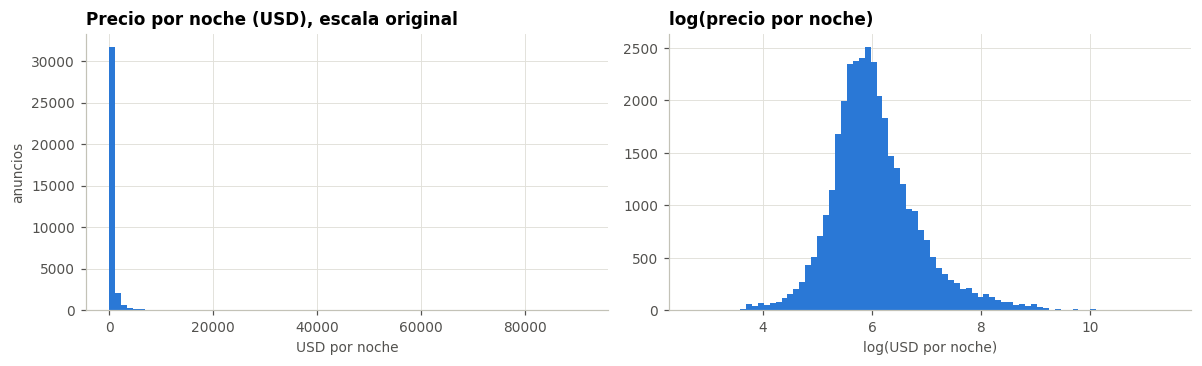

In [27]:
print(df["price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2).to_string())
print(f"\nAsimetría del precio: {df['price'].skew():.1f}   |   Asimetría de log(precio): {np.log(df['price']).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(df["price"], bins=80, color=AZUL)
axes[0].set_title("Precio por noche (USD), escala original")
axes[0].set_xlabel("USD por noche"); axes[0].set_ylabel("anuncios")
axes[1].hist(np.log(df["price"]), bins=80, color=AZUL)
axes[1].set_title("log(precio por noche)")
axes[1].set_xlabel("log(USD por noche)")
plt.tight_layout()
plt.show()

El precio tiene una cola derecha extrema (máximo de más de 90 000 USD por noche frente a una mediana cercana a 380 USD). En escala logarítmica la distribución es mucho más simétrica, así que el criterio de outliers se aplica **sobre log(precio)** con la regla de Tukey: se consideran atípicos los valores fuera de `[Q1 − k·IQR, Q3 + k·IQR]`, con `k = 1.5`.

Aplicar la regla sobre la escala original eliminaría una fracción mucho mayor de anuncios de gama alta que son legítimos en Hawái.

Límites aceptados: 68 – 2,411 USD por noche
Atípicos bajos: 293 (0.8%)  |  Atípicos altos: 1,242 (3.5%)


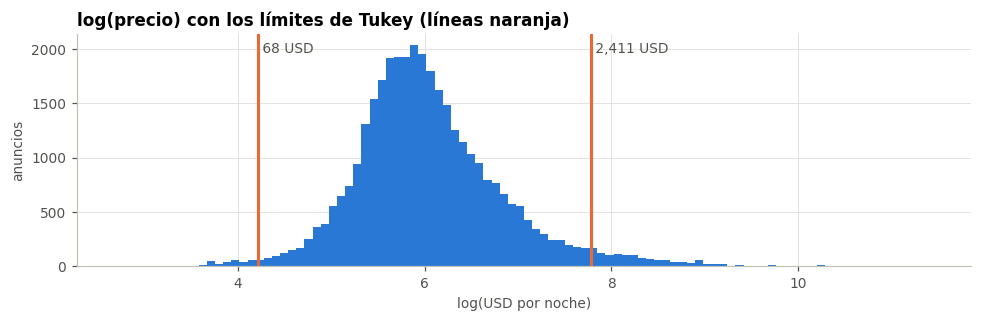

In [28]:
K_IQR = 1.5
lp = np.log(df["price"])
q1, q3 = lp.quantile([.25, .75])
lim_inf, lim_sup = np.exp(q1 - K_IQR * (q3 - q1)), np.exp(q3 + K_IQR * (q3 - q1))
bajo, alto = (df["price"] < lim_inf).sum(), (df["price"] > lim_sup).sum()
print(f"Límites aceptados: {lim_inf:,.0f} – {lim_sup:,.0f} USD por noche")
print(f"Atípicos bajos: {bajo:,} ({bajo/len(df):.1%})  |  Atípicos altos: {alto:,} ({alto/len(df):.1%})")

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(lp, bins=100, color=AZUL)
for v in (np.log(lim_inf), np.log(lim_sup)):
    ax.axvline(v, color=NARANJA, lw=2)
ax.text(np.log(lim_inf), ax.get_ylim()[1] * 0.92, f" {lim_inf:,.0f} USD", color="#52514e")
ax.text(np.log(lim_sup), ax.get_ylim()[1] * 0.92, f" {lim_sup:,.0f} USD", color="#52514e")
ax.set_title("log(precio) con los límites de Tukey (líneas naranja)")
ax.set_xlabel("log(USD por noche)"); ax.set_ylabel("anuncios")
plt.tight_layout()
plt.show()

In [29]:
n0 = len(df)
df = df[(df["price"] >= lim_inf) & (df["price"] <= lim_sup)].reset_index(drop=True)
print(f"Registros: {n0:,} -> {len(df):,}  (se eliminan {n0 - len(df):,}, {1 - len(df)/n0:.1%})")

Registros: 35,125 -> 33,590  (se eliminan 1,535, 4.4%)


### 8.2 Variables predictoras
Para las predictoras no se eliminan filas (se perdería información del precio, que sí es válida). Se revisan las colas y los valores extremos se **acotan** (*winsorización*) al percentil 99, salvo donde hay un tope con sentido de negocio.

In [30]:
cols_cola = ["accommodates", "bedrooms", "beds", "bathrooms", "minimum_nights", "maximum_nights",
             "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "reviews_per_month",
             "calculated_host_listings_count", "estimated_occupancy_l365d", "n_amenities",
             "quote_nights", "quote_lead_days", "days_since_last_review", "months_since_first_review"]
antes = df[cols_cola].describe(percentiles=[.5, .99]).T[["min", "50%", "99%", "max"]]
antes["asimetría"] = df[cols_cola].skew()
antes.round(2)

,min,50%,99%,max,asimetría
accommodates,1.0,4.00,14.00,1.600000e+01,1.49
bedrooms,0.0,1.00,5.00,1.500000e+01,1.30
beds,1.0,2.00,8.00,2.600000e+01,2.15
bathrooms,0.0,1.00,4.50,1.000000e+01,1.83
minimum_nights,1.0,2.00,90.00,3.650000e+02,9.26
maximum_nights,1.0,365.00,1125.00,2.147484e+09,39.96
number_of_reviews,0.0,10.00,396.00,1.682000e+03,4.46
number_of_reviews_ltm,0.0,2.00,57.00,5.210000e+02,4.21
number_of_reviews_l30d,0.0,0.00,5.00,3.900000e+01,7.45
reviews_per_month,0.0,0.38,5.12,2.542000e+01,2.93


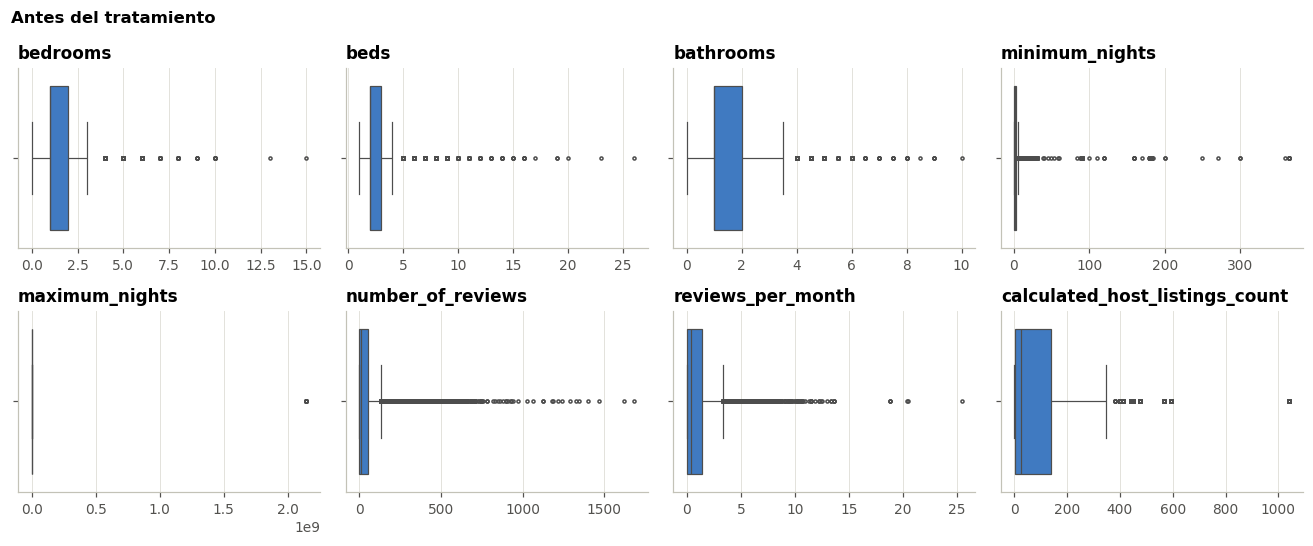

In [31]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, c in zip(axes.ravel(), ["bedrooms", "beds", "bathrooms", "minimum_nights",
                                "maximum_nights", "number_of_reviews", "reviews_per_month", "calculated_host_listings_count"]):
    sns.boxplot(x=df[c], ax=ax, color=AZUL, fliersize=2, linewidth=0.8)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Antes del tratamiento", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

In [32]:
# Topes con sentido de negocio
df["maximum_nights"] = df["maximum_nights"].clip(upper=1125)   # 1125 es el máximo que permite Airbnb; valores mayores son centinelas
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)    # más de un año de estancia mínima no es un alquiler vacacional

# Winsorización al percentil 99 para el resto de colas largas
cols_p99 = ["bedrooms", "beds", "bathrooms", "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d",
            "reviews_per_month", "calculated_host_listings_count", "n_amenities", "quote_nights", "quote_lead_days",
            "days_since_last_review", "months_since_first_review"]
topes = {}
for c in cols_p99:
    topes[c] = df[c].quantile(0.99)
    df[c] = df[c].clip(upper=topes[c])

despues = df[cols_cola].describe(percentiles=[.5, .99]).T[["min", "50%", "99%", "max"]]
despues["asimetría"] = df[cols_cola].skew()
comparacion = pd.DataFrame({"máx. antes": antes["max"], "máx. después": despues["max"],
                            "asimetría antes": antes["asimetría"], "asimetría después": despues["asimetría"]})
comparacion.round(2)

,máx. antes,máx. después,asimetría antes,asimetría después
accommodates,1.600000e+01,16.00,1.49,1.49
bedrooms,1.500000e+01,5.00,1.30,0.79
beds,2.600000e+01,8.00,2.15,1.26
bathrooms,1.000000e+01,4.50,1.83,1.28
minimum_nights,3.650000e+02,365.00,9.26,9.26
maximum_nights,2.147484e+09,1125.00,39.96,0.47
number_of_reviews,1.682000e+03,396.00,4.46,2.61
number_of_reviews_ltm,5.210000e+02,57.00,4.21,1.83
number_of_reviews_l30d,3.900000e+01,5.00,7.45,2.32
reviews_per_month,2.542000e+01,5.12,2.93,1.61


### 8.3 Coherencia geográfica y lógica

In [33]:
en_hawai = df["latitude"].between(18.5, 22.5) & df["longitude"].between(-160.5, -154.5)
print(f"Coordenadas dentro del archipiélago: {en_hawai.mean():.1%}")
print(f"Puntajes de reseña fuera de [1, 5]: {int((~df[cols_score].apply(lambda s: s.between(1, 5))).sum().sum())}")
print(f"Disponibilidades fuera de rango: {int((~df['availability_30'].between(0, 30)).sum() + (~df['availability_365'].between(0, 365)).sum())}")
print(f"Anuncios con mínimo de noches > máximo de noches: {int((df['minimum_nights'] > df['maximum_nights']).sum())}")

Coordenadas dentro del archipiélago: 100.0%
Puntajes de reseña fuera de [1, 5]: 0
Disponibilidades fuera de rango: 0
Anuncios con mínimo de noches > máximo de noches: 0


In [34]:
# Corrección de las incoherencias mín. > máx. (el máximo se iguala al mínimo)
df["maximum_nights"] = df[["minimum_nights", "maximum_nights"]].max(axis=1)

## 9. Codificación

- **Numéricas:** todas quedan como `int`/`float`. Se agrega `log_price` (objetivo recomendado para la regresión, por la asimetría vista en 8.1).
- **Booleanas:** ya codificadas como 0/1.
- **Categóricas:** `room_type`, `island`, `neighbourhood`, `property_group` y `host_location_group` se codifican *one-hot* en el conjunto para modelos. Son nominales (sin orden), por lo que no se usa codificación ordinal.
- **Fecha:** `price_quote_checkin_date` queda en formato ISO `AAAA-MM-DD` en el conjunto limpio; en el conjunto para modelos se representa con `quote_checkin_month` y `quote_lead_days`.

El **escalado** (estandarización) de las numéricas no se guarda en el archivo a propósito: debe ajustarse solo con los datos de entrenamiento dentro del *pipeline* de cada modelo para no filtrar información del conjunto de prueba. Al final de esta sección hay un ejemplo.

In [35]:
df["log_price"] = np.log(df["price"])

# Tipos enteros donde corresponde
enteras = ["accommodates", "minimum_nights", "maximum_nights", "availability_30", "availability_365",
           "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "estimated_occupancy_l365d",
           "calculated_host_listings_count", "n_amenities", "quote_nights", "quote_lead_days", "quote_checkin_month",
           "days_since_last_review", "host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
df[enteras] = df[enteras].round().astype(int)

# Orden final de columnas del conjunto limpio
orden = (["id", "price", "log_price", "island", "neighbourhood", "latitude", "longitude",
          "room_type", "property_group", "accommodates", "bedrooms", "beds", "bathrooms", "bath_shared",
          "minimum_nights", "maximum_nights", "long_stay", "has_availability", "availability_30", "availability_365",
          "estimated_occupancy_l365d",
          "price_quote_checkin_date", "quote_checkin_month", "quote_nights", "quote_lead_days",
          "host_is_superhost", "host_has_profile_pic", "host_identity_verified", "host_years",
          "host_location_group", "calculated_host_listings_count", "has_license",
          "has_reviews", "number_of_reviews", "number_of_reviews_ltm", "number_of_reviews_l30d", "reviews_per_month",
          "days_since_last_review", "months_since_first_review"] + cols_score + ["n_amenities"] + list(PATRONES))
assert set(orden) == set(df.columns), set(orden) ^ set(df.columns)
clean = df[orden].copy()

# Conjunto para modelos: one-hot de las categóricas, sin id ni fecha
CATEGORICAS = ["room_type", "island", "neighbourhood", "property_group", "host_location_group"]
model = pd.get_dummies(clean.drop(columns=["id", "price_quote_checkin_date"]), columns=CATEGORICAS, dtype=int)
model.columns = [re.sub(r"[^0-9a-zA-Z_]+", "_", c).strip("_").lower() for c in model.columns]

print(f"Conjunto limpio:      {clean.shape[0]:,} filas x {clean.shape[1]} columnas")
print(f"Conjunto para modelos: {model.shape[0]:,} filas x {model.shape[1]} columnas (todas numéricas)")

Conjunto limpio:      33,590 filas x 64 columnas
Conjunto para modelos: 33,590 filas x 104 columnas (todas numéricas)


In [36]:
# Ejemplo de escalado correcto (no modifica los archivos exportados)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = model.drop(columns=["price", "log_price"])
X_train, X_test = train_test_split(X, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)            # se ajusta SOLO con entrenamiento
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Media y desviación de las 3 primeras variables escaladas (entrenamiento):",
      X_train_s[:, :3].mean(axis=0).round(2), X_train_s[:, :3].std(axis=0).round(2))

Media y desviación de las 3 primeras variables escaladas (entrenamiento): [ 0. -0.  0.] [1. 1. 1.]


## 10. Validación final y exportación

In [37]:
# Comprobaciones automáticas de los requisitos del entregable
assert clean.isna().sum().sum() == 0 and model.isna().sum().sum() == 0, "Hay datos faltantes"
assert clean["id"].is_unique, "Hay IDs repetidos"
assert all(pd.api.types.is_numeric_dtype(t) for t in model.dtypes), "Hay columnas no numéricas en el conjunto para modelos"
assert pd.api.types.is_datetime64_any_dtype(clean["price_quote_checkin_date"])
assert not np.isinf(model.to_numpy(dtype=float)).any()
assert model.nunique().min() > 1, "Hay columnas constantes"
print("Validaciones superadas: sin faltantes, sin duplicados, tipos consistentes, sin columnas constantes.\n")

resumen_tipos = clean.dtypes.astype(str).replace({"object": "texto (categórica)", "str": "texto (categórica)"})
resumen_tipos = resumen_tipos.str.replace(r"datetime64.*", "fecha", regex=True)
print(resumen_tipos.value_counts().to_string())

Validaciones superadas: sin faltantes, sin duplicados, tipos consistentes, sin columnas constantes.

int64                 41
float64               17
texto (categórica)     5
fecha                  1


In [38]:
clean.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
id,33590.0,804286985141934592.0,5269.0,46775592.0,879771219624463232.0,1405315499116196352.0,1776541942099828992.0,649430483203125120.0
price,33590.0,495.152681,67.72,257.1225,375.495,594.0,2409.8,377.41956
log_price,33590.0,5.98394,4.215382,5.549553,5.928245,6.386879,7.787299,0.647183
latitude,33590.0,20.911404,18.98965,20.690606,20.958695,21.29242,22.22909,0.805887
longitude,33590.0,-157.210805,-159.716528,-157.83897,-156.69095,-156.435854,-154.84228,1.278549
accommodates,33590.0,4.790979,1.0,4.0,4.0,6.0,16.0,2.323719
bedrooms,33590.0,1.535755,0.0,1.0,1.0,2.0,5.0,1.022894
beds,33590.0,2.608961,1.0,2.0,2.0,3.0,8.0,1.397491
bathrooms,33590.0,1.596532,0.0,1.0,1.0,2.0,4.5,0.774853
bath_shared,33590.0,0.01432,0.0,0.0,0.0,0.0,1.0,0.118807


In [39]:
clean.to_csv(os.path.join(OUT_DIR, "listings_clean.csv"), index=False, date_format="%Y-%m-%d")
model.to_csv(os.path.join(OUT_DIR, "listings_model.csv"), index=False)
print("Archivos guardados: listings_clean.csv, listings_model.csv")
clean.head()

Archivos guardados: listings_clean.csv, listings_model.csv


,id,price,log_price,island,neighbourhood,latitude,longitude,room_type,property_group,accommodates,bedrooms,beds,bathrooms,bath_shared,minimum_nights,maximum_nights,long_stay,has_availability,availability_30,availability_365,estimated_occupancy_l365d,price_quote_checkin_date,quote_checkin_month,quote_nights,quote_lead_days,host_is_superhost,host_has_profile_pic,host_identity_verified,host_years,host_location_group,calculated_host_listings_count,has_license,has_reviews,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,reviews_per_month,days_since_last_review,months_since_first_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,n_amenities,am_wifi,am_kitchen,am_air_conditioning,am_free_parking,am_pool,am_hot_tub,am_washer,am_dishwasher,am_tv,am_bbq,am_beach_waterfront,am_ocean_view,am_gym,am_elevator,am_self_checkin,am_workspace,am_patio_balcony
0,784020,848.33,6.743270,Maui,Lahaina,20.995184,-156.665009,Entire home/apt,House,8,3.0,5.0,2.5,0,3,1125,0,1,15,192,162,2026-09-23,9,3,2,1,1,1,13.83,Hawaii,1,1,1,169,27,0,1.48,62,112.8,4.96,4.97,4.92,4.97,4.93,4.97,4.80,64,1,1,1,1,0,0,1,1,1,1,1,0,0,0,1,1,1
1,461638,101.86,4.623599,Hawaii,South Hilo,19.721000,-155.084950,Private room,House,1,1.0,1.0,1.0,1,7,180,0,1,30,90,42,2026-09-19,9,7,0,0,1,1,14.42,Hawaii,5,1,1,396,3,0,2.51,38,147.0,4.68,4.74,4.81,4.83,4.82,4.81,4.59,38,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
2,479121,265.00,5.579730,Hawaii,Puna,19.400310,-154.920430,Entire home/apt,House,6,1.0,7.0,2.0,0,1,1125,0,1,24,255,126,2026-09-23,9,1,4,1,1,1,13.33,Elsewhere,3,1,1,345,21,0,2.01,33,147.0,4.77,4.83,4.82,4.88,4.88,4.74,4.79,53,1,1,0,1,0,0,0,0,1,1,1,1,0,0,0,0,1
3,780183,450.83,6.111090,Maui,Kihei-Makena,20.685910,-156.434370,Entire home/apt,Condo,4,1.0,2.0,2.0,0,2,60,0,1,14,27,48,2026-09-27,9,2,7,1,1,1,13.83,Elsewhere,1,1,1,20,8,1,0.16,3,124.1,4.95,5.00,4.70,5.00,5.00,5.00,4.90,76,1,1,1,1,1,0,1,1,1,1,1,1,0,0,1,1,1
4,2038271,412.16,6.021412,Maui,Lahaina,20.972140,-156.679730,Private room,Hotel/Resort,4,1.0,2.0,1.0,0,180,1125,1,1,30,365,0,2026-09-19,9,90,0,0,1,0,15.67,Elsewhere,10,0,1,3,0,0,0.02,1817,147.0,4.67,5.00,5.00,5.00,5.00,4.67,4.67,18,1,1,1,1,1,0,1,0,1,0,1,0,1,1,0,0,0


### Diccionario del conjunto limpio

| Grupo | Variables |
|---|---|
| Objetivo | `price` (USD por noche), `log_price` |
| Ubicación | `island`, `neighbourhood`, `latitude`, `longitude` |
| Inmueble | `room_type`, `property_group`, `accommodates`, `bedrooms`, `beds`, `bathrooms`, `bath_shared` |
| Reglas y disponibilidad | `minimum_nights`, `maximum_nights`, `long_stay`, `has_availability`, `availability_30`, `availability_365`, `estimated_occupancy_l365d` |
| Cotización | `price_quote_checkin_date`, `quote_checkin_month`, `quote_nights`, `quote_lead_days` |
| Anfitrión | `host_is_superhost`, `host_has_profile_pic`, `host_identity_verified`, `host_years`, `host_location_group`, `calculated_host_listings_count`, `has_license` |
| Reseñas | `has_reviews`, `number_of_reviews`, `number_of_reviews_ltm`, `number_of_reviews_l30d`, `reviews_per_month`, `days_since_last_review`, `months_since_first_review`, `review_scores_*` (7) |
| Amenidades | `n_amenities` y 17 indicadores `am_*` |

**Nota para la etapa de modelos.** `estimated_occupancy_l365d` y las variables de reseñas describen el desempeño pasado del anuncio. Son útiles para definir la etiqueta *recomendado / no recomendado*, pero un anfitrión nuevo no las tiene; para el modelo de precio de un inmueble nuevo conviene excluirlas o fijarlas en sus valores "sin historial".

---
## 11. Resumen para el reporte (máximo 1 página)

**Conjunto de datos inicial.** Archivo `listings.csv` detallado de Inside Airbnb para Hawái (scrape de septiembre de 2026): **38 779 anuncios y 90 variables** (36 decimales, 30 de texto, 24 enteras), sin registros duplicados.

**Hallazgos.**
- 13 variables llegan completamente vacías (entre ellas `bathrooms`, `host_since`, `host_response_rate`, `instant_bookable`).
- `price` viene como texto y corresponde al precio por noche de una cotización para fechas concretas; falta en el 9.4 % de los anuncios (no disponibles, sin cotización o con tarifa solo mensual).
- Las variables de reseñas faltan en cerca del 23 % de los anuncios: son los que no tienen ninguna reseña.
- Booleanos como `t`/`f`, fechas como texto, amenidades como lista JSON con más de 6 600 textos distintos, y 84 tipos de propiedad.
- Valores extremos: precio de hasta 91 455 USD por noche (mediana 384 USD) y `maximum_nights` con el valor centinela 2 147 483 647.

**Procedimientos.**
1. **Selección de variables:** se descartan las vacías, identificadores y URLs, texto libre, metadatos del scrape, variables redundantes (correlación ≥ 0.82 con la que se conserva) y las que se calculan a partir del precio (fuga de información).
2. **Tipos y formatos:** precio a número, booleanos a 0/1, fechas a `datetime`.
3. **Variable objetivo:** se eliminan los 3 654 anuncios sin precio; no se imputa la variable que se va a predecir.
4. **Nuevas características:** número de baños y baño compartido (desde `bathrooms_text`), años como anfitrión, licencia registrada, residencia del anfitrión, noches / anticipación / mes de la cotización, antigüedad y recencia de las reseñas, número de amenidades y 17 indicadores de amenidades, estancia larga (≥ 30 noches) y tipo de edificación (6 grupos).
5. **Datos faltantes:** calificaciones con la mediana más el indicador `has_reviews`; `reviews_per_month` con 0; camas, habitaciones y baños con la mediana de anuncios del mismo tipo y capacidad; noches mínimas y máximas con su promedio de 12 meses.
6. **Outliers:** en el precio, regla de Tukey (k = 1.5) sobre log(precio), que conserva el rango de 68 a 2 411 USD y elimina 1 535 anuncios (4.4 %); en las predictoras, acotamiento al percentil 99 y topes de negocio (`maximum_nights` ≤ 1 125).
7. **Codificación:** *one-hot* para las cinco variables categóricas; se agrega `log_price`. El escalado se deja para el *pipeline* de cada modelo, ajustado solo con datos de entrenamiento.

**Conjunto de datos final.** **33 590 anuncios** (86.6 % del original) sin datos faltantes ni duplicados:
- `listings_clean.csv`: 64 variables (41 enteras, 17 decimales, 5 categóricas, 1 fecha), para el análisis exploratorio y el tablero.
- `listings_model.csv`: 104 variables, todas numéricas, para los modelos.

In [41]:
import sys
 
import pandas as pd
 
entrada ="listings.csv"
salida ="hosts.csv"
 
hosts = pd.read_csv(entrada, usecols=["id", "host_id"])
hosts.to_csv(salida, index=False)
print(f"{salida}: {len(hosts):,} anuncios, {hosts['host_id'].nunique():,} anfitriones")

hosts.csv: 38,779 anuncios, 9,306 anfitriones
